# Implementación CARP para recolección de residuos

## 1. Datos de la instancia


- \(P=2\): número de vehículos.
- \(W=15000\): capacidad de cada vehículo.
- \(n=10\): número de nodos internos.
- \(m=7\): número de arcos que requieren recolectar basura.

Los arcos requeridos son

$$
A_R=\{(1,2),(3,4),(2,5),(5,6),(7,8),(9,10),(10,6)\}.
$$

### Observación importante sobre $(L$)

Con las demandas utilizadas en este cuaderno,

$$
5000,\;5000,\;5000,\;2500,\;2500,\;2000,\;2000,
$$

y $(W=15000)$, la cota construida a partir de la capacidad da

$$
\ell=3,\qquad
L_{\text{cap}}=\left\lceil\frac{7}{3}\right\rceil=3.
$$

Sin embargo, la formulación completa del paper considera (P) viajes iniciales y (P) viajes finales. Con (P=2) se necesitan al menos

$
2P=4
$

índices de viaje. Por ello, **sin cambiar las demandas ni la capacidad**, se usa para la implementación la cota más holgada

$
L=\max\{L_{\text{cap}},2P\}=4.
$



In [2]:

import math
from itertools import combinations

import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt



## 1. Definición del grafo

Usaremos:

- \(V\): conjunto de todos los nodos.
- \(U\): nodos internos de la zona de recolección.
- \(A\): conjunto de todos los arcos que pueden recorrerse.
- \(A_R\subseteq A\): arcos que requieren servicio.

Donde,

- `s` representa la **base de la cuadrilla**;
- `t` representa la **instalación de descarga o reciclaje**;
- los nodos `1,...,10` representan intersecciones internas.


In [3]:

# Nodos internos
U = [str(i) for i in range(1,11)]

# Todos los nodos
V = ["s"] + U + ["t"]

# Conjunto de arcos
A = gp.tuplelist([
    ("s","1"), ("1","s"), ("s","3"),
    ("1","2"), ("2","1"),
    ("2","3"),
    ("3","4"), ("4","3"),
    ("4","5"),
    ("2","5"), ("5","2"),
    ("5","6"), ("6","5"),
    ("6","7"), ("7","6"),
    ("7","8"), ("8","7"),
    ("8","9"), ("9","8"),
    ("9","10"), ("10","9"),
    ("10","6"), ("6","10"),
    ("2","t"), ("t","8"),
    ("8","t"), ("9","t"), ("6", "t")
])

# Arcos que requieren recolección
AR = gp.tuplelist([
    ("1","2"),
    ("3","4"),
    ("2","5"),
    ("5","6"),
    ("7","8"),
    ("9","10"),
    ("10","6")
])

print("Nodos internos:", len(U))
print("Arcos totales:", len(A))
print("Arcos requeridos:", len(AR))
print("Arcos no requeridos:", len(A)-len(AR))


Nodos internos: 10
Arcos totales: 28
Arcos requeridos: 7
Arcos no requeridos: 21



## 2. Demandas, capacidad y número de viajes

Sea $(q_{ij})$ la cantidad de residuos recogida en el arco requerido $((i,j))$.

Primero se calcula $(\ell)$ como el mayor número de demandas, ordenadas de mayor a menor, cuya suma no supera la capacidad (W). Luego,

$$
L_{\text{cap}}=
\left\lceil\frac{m}{\ell}\right\rceil.
$$

Como en esta instancia se desea aplicar la estructura completa del paper con \(P=2\), se utilizará

$$
L=\max\{L_{\text{cap}},2P\}.
$$


In [4]:

# Número de vehículos
P = 2

# Capacidad de cada vehículo
W = 15000

# Demandas: se conservan exactamente las del avance
q = {
    ("1","2"): 5000,
    ("3","4"): 5000,
    ("2","5"): 2000,
    ("5","6"): 2500,
    ("7","8"): 2000,
    ("9","10"): 5000,
    ("10","6"): 2500
}

m = len(AR)

# Demandas ordenadas de mayor a menor
demandas = sorted(q.values(), reverse=True)

# Cálculo de ell
acumulado = 0
ell = 0

for demanda in demandas:
    if acumulado + demanda <= W:
        acumulado += demanda
        ell += 1
    else:
        break

# Cota obtenida únicamente a partir de capacidad
L_cap = math.ceil(m/ell)

# Para poder representar P viajes iniciales y P finales
L = max(L_cap, 2*P)

print("Demandas ordenadas:", demandas)
print("ell =", ell)
print("L por capacidad =", L_cap)
print("2P =", 2*P)
print("L usado en el modelo =", L)


Demandas ordenadas: [5000, 5000, 5000, 2500, 2500, 2000, 2000]
ell = 3
L por capacidad = 3
2P = 4
L usado en el modelo = 4



Con \(P=2\) y \(L=4\):

- \(r=1,2\): viajes iniciales, desde `s` hasta `t`;
- \(r=3,4\): viajes finales, desde `t` hasta `s`;
- no existen viajes intermedios en esta instancia.



In [5]:

R = list(range(1,L+1))

R_iniciales = list(range(1,P+1))
R_finales = list(range(P+1,2*P+1))
R_intermedios = list(range(2*P+1,L+1))



In [6]:
# Viajes en los que sí está permitido recoger residuos
# Se excluyen los viajes finales
R_servicio = R_iniciales + R_intermedios

print("Todos los viajes:", R)
print("Viajes iniciales:", R_iniciales)
print("Viajes finales:", R_finales)
print("Viajes intermedios:", R_intermedios)
print("Viajes que pueden prestar servicio:", R_servicio)

Todos los viajes: [1, 2, 3, 4]
Viajes iniciales: [1, 2]
Viajes finales: [3, 4]
Viajes intermedios: []
Viajes que pueden prestar servicio: [1, 2]



También es útil calcular una **cota inferior** sencilla para el número de viajes a partir de la demanda total:

$$
\left\lceil\frac{Q_T}{W}\right\rceil,
\qquad
Q_T=\sum_{(i,j)\in A_R}q_{ij}.
$$

Esta cantidad no es lo mismo que $(L)$:

- $(\lceil Q_T/W\rceil)$ es una cota inferior por capacidad;
- $(L)$ es la cota superior construida con el procedimiento usado en el paper.


In [7]:

QT = sum(q[i,j] for (i,j) in AR)
cota_inferior = math.ceil(QT/W)

print("Demanda total =", QT)
print("Cota inferior por capacidad =", cota_inferior)
print("L usado en el modelo =", L)


Demanda total = 24000
Cota inferior por capacidad = 2
L usado en el modelo = 4


In [8]:
# Verificación de capacidad disponible para los viajes que pueden prestar servicio

capacidad_servicio = len(R_servicio) * W

print("Demanda total:", QT)
print("Número de viajes que pueden recoger:", len(R_servicio))
print("Capacidad total disponible para recolección:", capacidad_servicio)

if QT <= capacidad_servicio:
    print("La instancia puede ser factible desde el punto de vista de capacidad.")
else:
    print("No existe capacidad suficiente para prohibir servicio en los viajes finales.")

Demanda total: 24000
Número de viajes que pueden recoger: 2
Capacidad total disponible para recolección: 30000
La instancia puede ser factible desde el punto de vista de capacidad.



## 3. Gráfico de la instancia

Los arcos requeridos se muestran con mayor grosor. Los demás arcos pueden ser utilizados para desplazamientos sin servicio (*deadheading*).


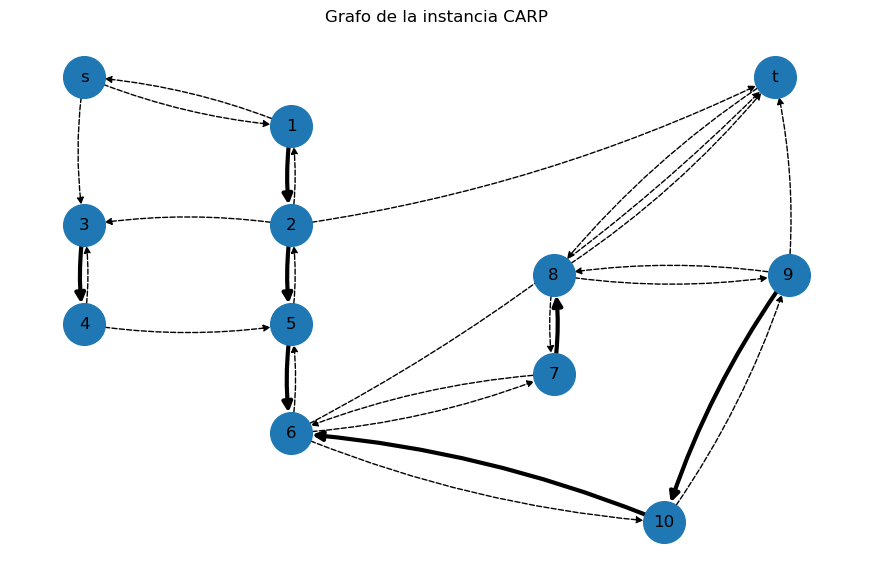

In [9]:
from matplotlib import pyplot

D = nx.DiGraph()
D.add_nodes_from(V)
D.add_edges_from(A)

# Posiciones similares al dibujo original
pos = {
    "s": (0, 5),
    "1": (1.5, 4.5),
    "2": (1.5, 3.5),
    "3": (0, 3.5),
    "4": (0, 2.5),
    "5": (1.5, 2.5),
    "6": (1.5, 1.4),
    "7": (3.4, 2.0),
    "8": (3.4, 3.0),
    "9": (5.1, 3.0),
    "10": (4.2, 0.5),
    "t": (5.0, 5.0)
}

A_no_requeridos = [a for a in A if a not in AR]

plt.figure(figsize=(11, 7))
nx.draw_networkx_nodes(D, pos, node_size=900)
nx.draw_networkx_labels(D, pos)

# Aristas no requeridas (discontinuas)
nx.draw_networkx_edges(
    D, pos,
    edgelist=A_no_requeridos,
    arrows=True,
    node_size=900,   # <-- ¡Añadido para mostrar las flechas!
    arrowsize=10,    # <-- Tamaño de la punta de la flecha
    width=1,
    style="dashed",
    connectionstyle="arc3,rad=0.08"
)

# Aristas requeridas (resaltadas)
nx.draw_networkx_edges(
    D, pos,
    edgelist=AR,
    arrows=True,
    node_size=900,   # <-- ¡Añadido para mostrar las flechas!
    arrowsize=14,    # <-- Tamaño de la punta de la flecha para aristas más gruesas
    width=3,
    connectionstyle="arc3,rad=0.08"
)

plt.title("Grafo de la instancia CARP")
plt.axis("off")
plt.show()



# 4. Formulación del modelo

### Variables principales

Para cada viaje $(r)$:

$$
x_{ij}^r=
\begin{cases}
1,&\text{si el arco requerido }(i,j)\text{ se sirve en el viaje }r,\\
0,&\text{caso contrario.}
\end{cases}
$$

Además,

$$
y_{ij}^r=
\text{número de veces que }(i,j)\text{ se recorre sin prestar servicio}.
$$



## 4.1 Función objetivo

Se consideran:

- $c_{ij}$: costo de recorrer el arco requerido $(i,j)$ prestando servicio;
- $d_{ij}$: costo de recorrer el arco $(i,j)$ sin prestar servicio
  (*deadheading*).

Para los arcos requeridos se considera:

$$
d_{ij}<c_{ij}, \qquad \forall (i,j)\in A_R.
$$

Los valores utilizados son datos simulados en unidades de costo.

La función objetivo es:

$$
\min
\sum_{r\in R}\sum_{(i,j)\in A_R}c_{ij}x_{ij}^r
+
\sum_{r\in R}\sum_{(i,j)\in A}d_{ij}y_{ij}^r.
$$

El primer término representa el costo asociado a prestar el servicio de
recolección y el segundo término representa el costo de los recorridos realizados
sin recoger residuos.

In [10]:
# d[i,j]: costo de recorrer el arco (i,j) sin prestar servicio

d = {
    ("s","1"): 4,
    ("1","s"): 4,
    ("s","3"): 5,

    ("1","2"): 2,
    ("2","1"): 2,
    ("2","3"): 2,

    ("3","4"): 3,
    ("4","3"): 3,
    ("4","5"): 2,

    ("2","5"): 3,
    ("5","2"): 3,

    ("5","6"): 2,
    ("6","5"): 2,

    ("6","7"): 4,
    ("7","6"): 4,

    ("7","8"): 2,
    ("8","7"): 2,

    ("8","9"): 3,
    ("9","8"): 3,

    ("9","10"): 2,
    ("10","9"): 2,

    ("10","6"): 3,
    ("6","10"): 3,

    ("2","t"): 6,
    ("t","8"): 6,

    ("6","t"): 6,
    ("8","t"): 6,
    ("9","t"): 6,
}

# c[i,j]: costo de recorrer un arco requerido prestando servicio.
# Se considera c[i,j] > d[i,j], porque recoger residuos
# genera un costo adicional respecto a solamente circular.

c = {
    ("1","2"): 4,
    ("3","4"): 5,
    ("2","5"): 5,
    ("5","6"): 4,
    ("7","8"): 4,
    ("9","10"): 4,
    ("10","6"): 5
}

print("Viajes potenciales R =", R)

print("\nCostos de servicio:")
for a in AR:
    print(a, "c =", c[a], "  d =", d[a])


Viajes potenciales R = [1, 2, 3, 4]

Costos de servicio:
('1', '2') c = 4   d = 2
('3', '4') c = 5   d = 3
('2', '5') c = 5   d = 3
('5', '6') c = 4   d = 2
('7', '8') c = 4   d = 2
('9', '10') c = 4   d = 2
('10', '6') c = 5   d = 3


In [11]:

# Crear modelo
model = gp.Model("CARP_basico")

# Restricción (15): variables binarias de servicio
x = model.addVars(
    [(r,i,j) for r in R for (i,j) in AR],
    vtype=GRB.BINARY,
    name="x"
)

# Restricción (16): variables enteras no negativas de deadheading
y = model.addVars(
    [(r,i,j) for r in R for (i,j) in A],
    vtype=GRB.INTEGER,
    lb=0,
    name="y"
)


Restricted license - for non-production use only - expires 2027-11-29



Para simplificar la escritura del código definimos `recorrido(r,i,j)`:

- si $((i,j)\in A_R)$, el arco puede recorrerse por servicio o por deadheading, de modo que aparece$\(x_{ij}^r+y_{ij}^r)$;
- si $((i,j)\notin A_R)$, solamente aparece $(y_{ij}^r)$.

Esta función es únicamente una abreviación de código; no introduce nuevas variables.


In [12]:

def recorrido(r,i,j):
    if (i,j) in AR:
        return x[r,i,j] + y[r,i,j]
    else:
        return y[r,i,j]


In [13]:

#  función objetivo
model.setObjective(
    gp.quicksum(
        c[i,j]*x[r,i,j]
        for r in R
        for (i,j) in AR
    )
    +
    gp.quicksum(
        d[i,j]*y[r,i,j]
        for r in R
        for (i,j) in A
    ),
    GRB.MINIMIZE
)



## 5. Restricciones (2)–(16)

Se implementan las restricciones en el mismo orden conceptual del paper:

- (2): continuidad en nodos internos;
- (3)–(5): viajes iniciales;
- (6)–(8): viajes finales;
- **(RF): los viajes finales no pueden prestar servicio de recolección;**
- (9)–(11): viajes intermedios;
- (12): conectividad;
- (13): capacidad;
- (14): servicio exactamente una vez;
- (15)–(16): dominio de las variables.



Para escribir las restricciones de flujo de manera clara, definimos una pequeña función.

Si un arco es requerido, el número total de veces que se recorre durante el viaje es

$$
x_{ij}^r+y_{ij}^r.
$$

Si no es requerido, solamente aparece $(y_{ij}^r)$.


In [14]:

# ---------------------------------------------------------
# (2) CONTINUIDAD EN LOS NODOS INTERNOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == v
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == v
        )
        == 0
        for v in U
        for r in R
    ),
    name="R2_continuidad"
)


# ---------------------------------------------------------
# (3) VIAJES INICIALES: balance en s
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 1
        for r in R_iniciales
    ),
    name="R3"
)


# ---------------------------------------------------------
# (4) VIAJES INICIALES: llegan una vez a t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 1
        for r in R_iniciales
    ),
    name="R4"
)


# ---------------------------------------------------------
# (5) VIAJES INICIALES: no salen de t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        == 0
        for r in R_iniciales
    ),
    name="R5"
)


# ---------------------------------------------------------
# (6) VIAJES FINALES: balance en s
# ---------------------------------------------------------
model.addConstrs(
    (
        -gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        +
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 1
        for r in R_finales
    ),
    name="R6"
)


# ---------------------------------------------------------
# (7) VIAJES FINALES: salen una vez de t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        == 1
        for r in R_finales
    ),
    name="R7"
)


# ---------------------------------------------------------
# (8) VIAJES FINALES: no vuelven a entrar a t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 0
        for r in R_finales
    ),
    name="R8"
)


# ---------------------------------------------------------
# (9) BALANCE EN s PARA VIAJES INTERMEDIOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 0
        for r in R_intermedios
    ),
    name="R9"
)


# ---------------------------------------------------------
# (10) BALANCE EN t PARA VIAJES INTERMEDIOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        -
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 0
        for r in R_intermedios
    ),
    name="R10"
)


# ---------------------------------------------------------
# (11) COMO MÁXIMO UNA SALIDA DE t EN UN VIAJE INTERMEDIO
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        <= 1
        for r in R_intermedios
    ),
    name="R11"
)


{}

### Restricción adicional: prohibición de recolección en los viajes finales

Se desea imponer una condición operativa adicional:
**los viajes finales no pueden recoger residuos**.

Recordemos que

$$
x_{ij}^r =
\begin{cases}
1, & \text{si el arco requerido }(i,j)\text{ es servido durante el viaje }r,\\
0, & \text{caso contrario.}
\end{cases}
$$

Los viajes finales están definidos por

$$
R_F=\{P+1,\ldots,2P\}.
$$

Por tanto, prohibir la recolección durante estos viajes equivale a imponer

$$
x_{ij}^r=0,
\qquad
\forall (i,j)\in A_R,\quad r\in R_F.
$$

De manera equivalente, como las variables $x_{ij}^r$ son binarias y no
negativas, para cada viaje final puede utilizarse la restricción agregada

$$
\sum_{(i,j)\in A_R}x_{ij}^r=0,
\qquad r\in R_F.
$$

Esto no impide que el vehículo recorra calles durante el viaje final.
El desplazamiento desde la instalación de descarga hasta la base continúa
representándose mediante las variables $y_{ij}^r$ de *deadheading*.

In [15]:
# ---------------------------------------------------------
# (RF) VIAJES FINALES SIN RECOLECCIÓN
# ---------------------------------------------------------
# Durante los viajes finales no se permite prestar
# servicio en ningún arco requerido.

model.addConstrs(
    (
        gp.quicksum(
            x[r,i,j]
            for (i,j) in AR
        )
        == 0
        for r in R_finales
    ),
    name="RF_no_servicio_final"
)

{3: <gurobi.Constr *Awaiting Model Update*>,
 4: <gurobi.Constr *Awaiting Model Update*>}

### Formulación compacta para la restricción de conectividad

La formulación anterior aunque permite representar correctamente la conectividad, el número de restricciones crece exponencialmente con el número de nodos,ya que el número de subconjuntos posibles es del orden de $2^{|V|}$.

Para evitar la enumeración de todos estos subconjuntos, se sustituye la
restricción (12) por una formulación compacta basada en un flujo auxiliar
de una mercancía (*Single Commodity Flow*).

La idea consiste en considerar que el nodo $t$, correspondiente a la
instalación de descarga, envía una unidad de flujo ficticio a cada nodo
utilizado durante un viaje.

Este flujo no representa residuos ni vehículos. Su única función es
garantizar conectividad.

Se introduce la variable binaria

$$
z_i^r =
\begin{cases}
1, & \text{si el nodo }i\text{ es utilizado durante el viaje }r,\\
0, & \text{caso contrario},
\end{cases}
$$

y variables continuas no negativas

$$
f_{ij}^r\geq 0,
$$

que representan el flujo auxiliar enviado entre nodos.

El flujo auxiliar solamente puede utilizar conexiones que formen parte
del recorrido del vehículo. De esta manera, si apareciera una componente
aislada, sus nodos deberían recibir flujo, pero dicho flujo no podría
llegar desde $t$, haciendo imposible esa solución. Para el flujo auxiliar se considera la conexión subyacente entre dos nodos,
independientemente de la dirección en que el vehículo la recorre.

Esto es necesario porque la restricción (12) original considera tanto los
arcos que entran a un subconjunto $S$ como los que salen de él. El flujo
auxiliar se utiliza únicamente para comprobar que existe conexión con $t$,
no para representar el sentido real de circulación del vehículo.

In [16]:
# ---------------------------------------------------------
# FORMULACIÓN COMPACTA DE CONECTIVIDAD
# Reemplaza la restricción (12)
# ---------------------------------------------------------

# Construimos el conjunto de conexiones no dirigidas
# que existen en el grafo.

E = []

for (i,j) in A:

    # Para evitar repetir la misma conexión:
    # (i,j) y (j,i) representan la misma conexión auxiliar.
    e = tuple(sorted([i,j]))

    if e not in E:
        E.append(e)

print("Número de conexiones auxiliares:", len(E))

# Para el flujo auxiliar permitimos ambos sentidos
# de cada conexión.

A_flujo = []

for (i,j) in E:

    A_flujo.append((i,j))
    A_flujo.append((j,i))

print("Arcos del flujo auxiliar:", len(A_flujo))



Número de conexiones auxiliares: 17
Arcos del flujo auxiliar: 34


In [28]:
V_sin_t = [v for v in V if v != "t"]
# ---------------------------------------------------------
# Variables auxiliares para conectividad compacta
# ---------------------------------------------------------

# z[r,v] = 1 si el nodo v es utilizado en el viaje r
# No necesitamos definir z para t, ya que t es la raíz
# de la conectividad.

z = model.addVars(
    [(r,v) for r in R for v in V_sin_t],
    vtype=GRB.BINARY,
    name="z"
)

# f[r,i,j] = flujo auxiliar enviado de i hacia j
# para demostrar conectividad con t.

f = model.addVars(
    [(r,i,j) for r in R for (i,j) in A_flujo],
    vtype=GRB.CONTINUOUS,
    lb=0,
    name="f"
)


#### Identificación de nodos utilizados

Para cada nodo $v\neq t$ se relaciona la variable $z_v^r$ con los arcos
utilizados durante el viaje.

Sea

$$
g_v^r=
\sum_{\substack{(i,j)\in A\\i=v\text{ o }j=v}}
(x_{ij}^r+y_{ij}^r),
$$

considerando $x_{ij}^r$ únicamente cuando $(i,j)\in A_R$.

Se imponen las restricciones

$$
z_v^r\leq g_v^r,
$$

y

$$
g_v^r\leq Mz_v^r.
$$

Por tanto:

- si ningún arco utilizado es incidente al nodo, entonces $z_v^r=0$;
- si algún arco utilizado es incidente al nodo, entonces $z_v^r=1$.

In [20]:
# ---------------------------------------------------------
# C1. Identificar los nodos utilizados en cada viaje
# ---------------------------------------------------------

M_con = 1000

for r in R:

    for v in V_sin_t:

        uso_nodo = gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == v or j == v
        )

        # Si z = 1, el nodo realmente debe ser utilizado
        model.addConstr(
            z[r,v] <= uso_nodo,
            name="C1a_{}_{}".format(r,v)
        )

        # Si el nodo es utilizado, z debe ser 1
        model.addConstr(
            uso_nodo <= M_con*z[r,v],
            name="C1b_{}_{}".format(r,v)
        )

#### Capacidad del flujo auxiliar

El flujo auxiliar solamente puede circular entre dos nodos si el vehículo
utiliza esa conexión durante el viaje.

Para cada conexión auxiliar se impone

$$
f_{ij}^r
\leq
(|V|-1)\,h_{ij}^r,
$$

donde $h_{ij}^r$ representa, mediante la expresión correspondiente en
$x$ e $y$, que la conexión entre $i$ y $j$ fue utilizada.

Si el vehículo no utiliza dicha conexión, el lado derecho es cero y,
por tanto,

$$
f_{ij}^r=0.
$$

In [21]:
# ---------------------------------------------------------
# C2. El flujo auxiliar solo puede circular
#     por conexiones utilizadas por el vehículo
# ---------------------------------------------------------

N_flujo = len(V_sin_t)

for r in R:

    for (i,j) in A_flujo:

        model.addConstr(
            f[r,i,j]
            <= N_flujo * uso_conexion(r,i,j),
            name="C2_{}_{}_{}".format(r,i,j)
        )

#### Balance del flujo en los nodos utilizados

Cada nodo utilizado distinto de $t$ debe recibir exactamente una unidad
neta de flujo auxiliar:

$$
\sum_{i:(i,v)\in A_f}f_{iv}^r
-
\sum_{j:(v,j)\in A_f}f_{vj}^r
=
z_v^r,
\qquad
v\neq t.
$$

Si $z_v^r=1$, el nodo debe recibir una unidad de flujo proveniente,
directa o indirectamente, desde $t$.

Si el nodo no forma parte del viaje, $z_v^r=0$ y no requiere flujo.

In [22]:
# ---------------------------------------------------------
# C3. Balance de flujo en todos los nodos distintos de t
# ---------------------------------------------------------

for r in R:

    for v in V_sin_t:

        flujo_entrada = gp.quicksum(
            f[r,i,j]
            for (i,j) in A_flujo
            if j == v
        )

        flujo_salida = gp.quicksum(
            f[r,i,j]
            for (i,j) in A_flujo
            if i == v
        )

        model.addConstr(
            flujo_entrada - flujo_salida == z[r,v],
            name="C3_{}_{}".format(r,v)
        )

#### Balance en la instalación de descarga

El nodo $t$ actúa como raíz de la conectividad.

Debe enviar una unidad de flujo por cada nodo utilizado durante el viaje:

$$
\sum_{j}f_{tj}^r
-
\sum_{i}f_{it}^r
=
\sum_{v\in V\setminus\{t\}}z_v^r.
$$

Por tanto, todo nodo que forma parte del recorrido debe ser alcanzable
desde $t$ mediante las conexiones utilizadas por el vehículo.

In [23]:
# ---------------------------------------------------------
# C4. El nodo t suministra todo el flujo auxiliar
# ---------------------------------------------------------

for r in R:

    flujo_sale_t = gp.quicksum(
        f[r,i,j]
        for (i,j) in A_flujo
        if i == "t"
    )

    flujo_entra_t = gp.quicksum(
        f[r,i,j]
        for (i,j) in A_flujo
        if j == "t"
    )

    model.addConstr(
        flujo_sale_t - flujo_entra_t
        ==
        gp.quicksum(z[r,v] for v in V_sin_t),
        name="C4_{}".format(r)
    )

In [24]:

# ---------------------------------------------------------
# (13) CAPACIDAD DE CADA VIAJE
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            q[i,j]*x[r,i,j]
            for (i,j) in AR
        )
        <= W
        for r in R
    ),
    name="R13_capacidad"
)


# ---------------------------------------------------------
# (14) CADA ARCO REQUERIDO SE SIRVE EXACTAMENTE UNA VEZ
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            x[r,i,j]
            for r in R
        )
        == 1
        for (i,j) in AR
    ),
    name="R14_servicio"
)

# (15) y (16) ya se impusieron al crear x e y.


{('1', '2'): <gurobi.Constr *Awaiting Model Update*>,
 ('3', '4'): <gurobi.Constr *Awaiting Model Update*>,
 ('2', '5'): <gurobi.Constr *Awaiting Model Update*>,
 ('5', '6'): <gurobi.Constr *Awaiting Model Update*>,
 ('7', '8'): <gurobi.Constr *Awaiting Model Update*>,
 ('9', '10'): <gurobi.Constr *Awaiting Model Update*>,
 ('10', '6'): <gurobi.Constr *Awaiting Model Update*>}

In [29]:

model.optimize()


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) i7-8850H CPU @ 2.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 337 rows, 680 columns and 1734 nonzeros (Min)
Model fingerprint: 0x6707fd7a
Model has 140 linear objective coefficients
Variable types: 408 continuous, 272 integer (160 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+03]
  Objective range  [2e+00, 6e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

MIP start from previous solve produced solution with objective 109 (0.01s)
Loaded MIP start from previous solve with objective 109

Presolve removed 183 rows and 535 columns
Presolve time: 0.01s
Presolved: 154 rows, 145 columns, 668 nonzeros
Variable types: 68 continuous, 77 integer (33 binary)

Root relaxation: cutoff, 30 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Curre


## 7. Solución

Para cada viaje activo se muestra:

- tipo de viaje;
- secuencia de nodos;
- arcos servidos;
- carga recogida;
- arcos recorridos sin servicio;
- costo de servicio;
- costo de deadheading.




In [42]:
# =========================================================
# RESUMEN DE LA SOLUCIÓN
# =========================================================

def informacion_viaje(r):
    """
    Recupera la información del viaje r:
    ruta, arcos servidos, carga recogida,
    deadheading y costos.
    """

    # Arcos servidos
    servidos = [
        (i,j)
        for (i,j) in AR
        if x[r,i,j].X > 0.5
    ]

    # Basura recogida
    carga = sum(
        q[i,j]
        for (i,j) in servidos
    )

    # Arcos recorridos sin servicio
    deadheading = []

    for (i,j) in A:

        veces = int(round(y[r,i,j].X))

        deadheading += [(i,j)] * veces

    # Costos
    costo_servicio = sum(
        c[i,j]
        for (i,j) in servidos
    )

    costo_deadheading = sum(
        d[i,j]
        for (i,j) in deadheading
    )

    costo_total = (
        costo_servicio
        +
        costo_deadheading
    )

    return {
        "ruta": rutas[r],
        "servidos": servidos,
        "carga": carga,
        "deadheading": deadheading,
        "costo_servicio": costo_servicio,
        "costo_deadheading": costo_deadheading,
        "costo_total": costo_total
    }


# =========================================================
# MOSTRAR SOLUCIÓN
# =========================================================

if model.status == GRB.Status.OPTIMAL:

    # Recuperar información de todos los viajes
    info_viajes = {
        r: informacion_viaje(r)
        for r in R
    }

    print()
    print("=" * 160)
    print("SOLUCIÓN ÓPTIMA DEL MODELO CARP")
    print("=" * 160)

    # -----------------------------------------------------
    # ENCABEZADO DE LA TABLA
    # -----------------------------------------------------

    print(
        f"{'Veh.':<6}"
        f"{'Viaje':<8}"
        f"{'Tipo':<12}"
        f"{'Basura':<10}"
        f"{'C. Serv.':<10}"
        f"{'C. Dead.':<10}"
        f"{'C. Total':<10}"
        f"{'Ruta'}"
    )

    print("-" * 160)

    # -----------------------------------------------------
    # FILAS DE LA TABLA
    # -----------------------------------------------------

    costos_vehiculos = {}

    for k in range(1, P + 1):

        viaje_inicial = k
        viaje_final = P + k

        costos_vehiculos[k] = 0

        for tipo, r in [
            ("Inicial", viaje_inicial),
            ("Final", viaje_final)
        ]:

            info = info_viajes[r]

            costos_vehiculos[k] += info["costo_total"]

            ruta_texto = " -> ".join(info["ruta"])

            print(
                f"{k:<6}"
                f"{r:<8}"
                f"{tipo:<12}"
                f"{info['carga']:<10}"
                f"{info['costo_servicio']:<10}"
                f"{info['costo_deadheading']:<10}"
                f"{info['costo_total']:<10}"
                f"{ruta_texto}"
            )

        # Separación entre vehículos
        print("-" * 160)


    # =====================================================
    # RESUMEN FINAL
    # =====================================================

    basura_total = sum(
        info_viajes[r]["carga"]
        for r in R
    )

    costo_total_calculado = sum(
        info_viajes[r]["costo_total"]
        for r in R
    )

    print()
    print("=" * 100)
    print("RESUMEN FINAL")
    print("=" * 100)

    print(
        f"{'Vehículo':<15}"
        f"{'Basura recogida':<20}"
        f"{'Costo total':<15}"
    )

    print("-" * 50)

    for k in range(1, P + 1):

        viaje_inicial = k
        viaje_final = P + k

        basura_vehiculo = (
            info_viajes[viaje_inicial]["carga"]
            +
            info_viajes[viaje_final]["carga"]
        )

        print(
            f"{k:<15}"
            f"{basura_vehiculo:<20}"
            f"{costos_vehiculos[k]:<15}"
        )

    print("-" * 50)

    print()
    print("Basura total recogida:", basura_total)
    print("Demanda total de la instancia:", QT)

    print(
        "Costo total calculado:",
        costo_total_calculado
    )

    print(
        "COSTO TOTAL ÓPTIMO DEL MODELO:",
        round(model.ObjVal, 2)
    )

else:

    print("No se obtuvo una solución óptima.")
    print("Estado de Gurobi:", model.status)


SOLUCIÓN ÓPTIMA DEL MODELO CARP
Veh.  Viaje   Tipo        Basura    C. Serv.  C. Dead.  C. Total  Ruta
----------------------------------------------------------------------------------------------------------------------------------------------------------------
1     1       Inicial     9500      13        10        23        s -> 1 -> 2 -> 5 -> 6 -> t
1     3       Final       0         0         23        23        t -> 8 -> 7 -> 6 -> 5 -> 2 -> 1 -> s
----------------------------------------------------------------------------------------------------------------------------------------------------------------
2     2       Inicial     14500     18        22        40        s -> 3 -> 4 -> 5 -> 6 -> 7 -> 8 -> 9 -> 10 -> 6 -> t
2     4       Final       0         0         23        23        t -> 8 -> 7 -> 6 -> 5 -> 2 -> 1 -> s
------------------------------------------------------------------------------------------------------------------------------------------------------------


## 8. Graficar las rutas obtenidas

Se dibuja una figura para cada viaje activo. Los arcos seleccionados por la solución aparecen con mayor grosor.


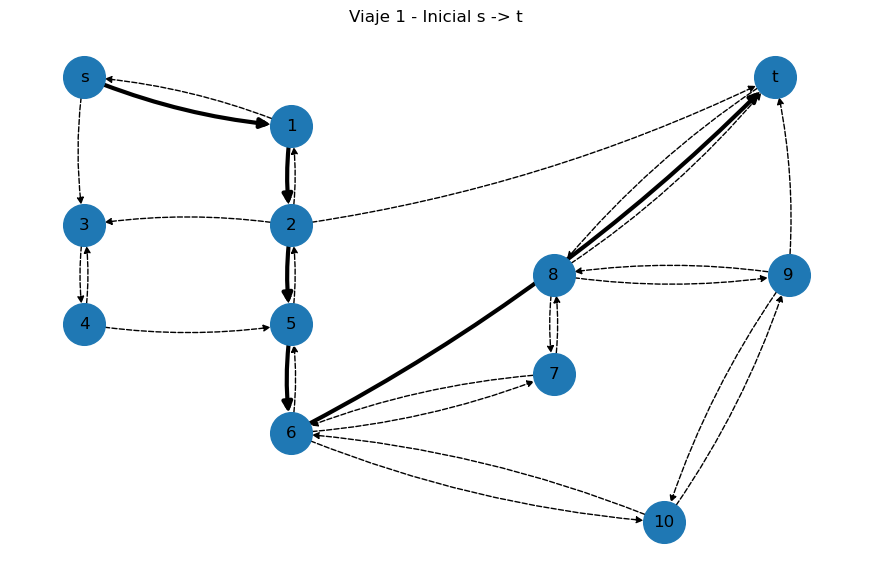

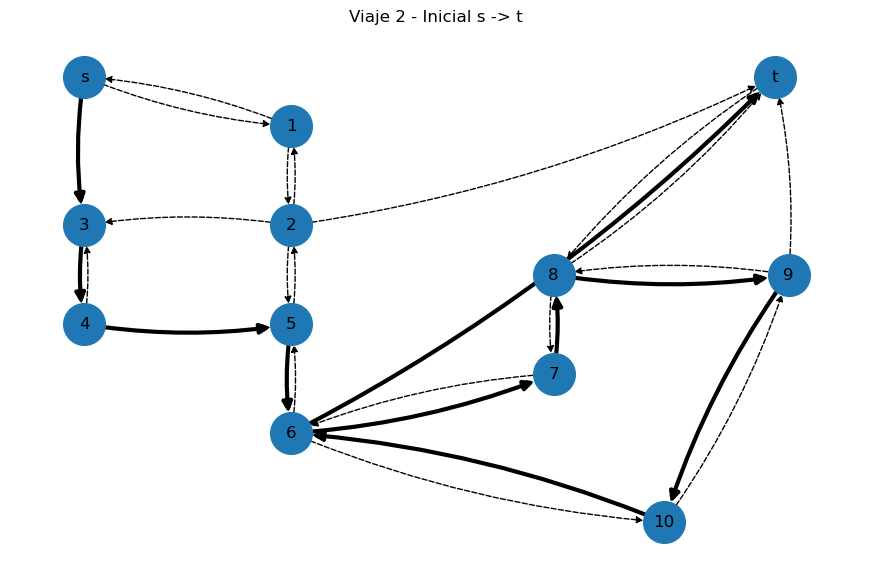

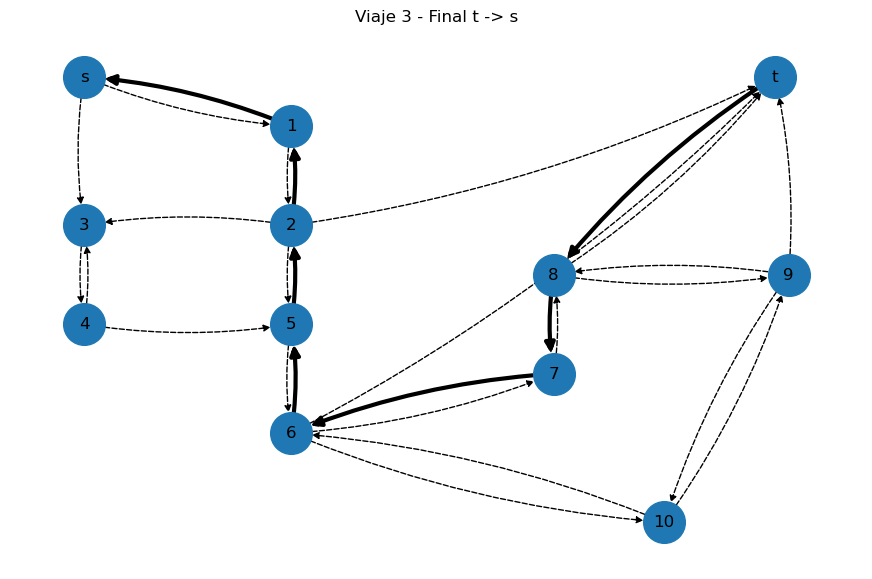

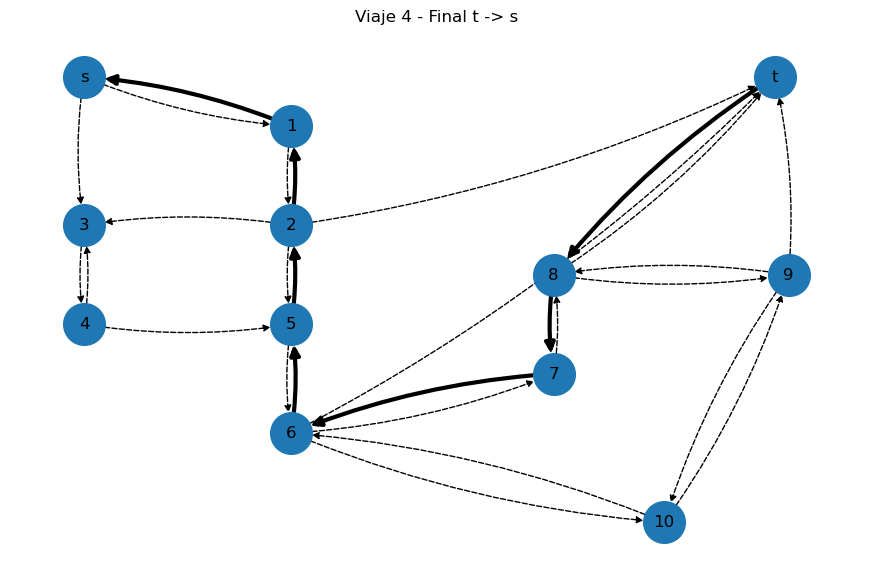

In [43]:

if model.status == GRB.Status.OPTIMAL:

    for r in R:

        arcos_r = []

        for (i,j) in A:

            veces = int(round(y[r,i,j].X))

            if (i,j) in AR and x[r,i,j].X > 0.5:
                veces += 1

            if veces > 0:
                arcos_r.append((i,j))

        plt.figure(figsize=(11,7))

        nx.draw_networkx_nodes(D, pos, node_size=900)
        nx.draw_networkx_labels(D, pos)

        nx.draw_networkx_edges(
            D, pos,
            edgelist=A,
            arrows=True,
            node_size=900,
            arrowsize=10,
            width=1,
            style="dashed",
            connectionstyle="arc3,rad=0.08"
        )

        nx.draw_networkx_edges(
            D, pos,
            edgelist=arcos_r,
            arrows=True,
            node_size=900,
            arrowsize=14,
            width=3,
            connectionstyle="arc3,rad=0.08"
        )

        if r in R_iniciales:
            tipo = "Inicial s -> t"
        elif r in R_finales:
            tipo = "Final t -> s"
        else:
            tipo = "Intermedio t -> t"

        plt.title("Viaje {} - {}".format(r,tipo))
        plt.axis("off")
        plt.show()
